# 04 - Evaluation and error analysis

The test set is used here for the first and only time per model. Change only `TAG` in the configuration cell to evaluate another model, then Restart and Run All.

In [1]:
import tensorflow as tf
for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)

import os
import sys
from pathlib import Path

REPO = next(
    (p for p in (Path("/workspace/NeuroVision"), Path.cwd().parent) if (p / "src" / "neurovision").exists()),
    None,
)
if REPO is None:
    raise RuntimeError("NeuroVision repo not found: edit REPO in this cell.")
sys.path.append(str(REPO / "src"))
os.chdir(REPO / "notebooks")
(REPO / "reports").mkdir(exist_ok=True)
print("Repo:", REPO)

2026-10-23 23:40:30.823880: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792798830.847986   48775 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792798830.855060   48775 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1792798830.873889   48775 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792798830.873921   48775 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792798830.873923   48775 computation_placer.cc:177] computation placer alr

Repo: /workspace/NeuroVision


## Configuration: which model to evaluate

In [2]:
MODELS = {
    "cnn": "../models/best_model.keras",
    "transfer": "../models/transfer_best.keras",
    "finetuned": "../models/finetuned_best.keras",  # use the file your fine-tuning notebook saves
}
TAG = "cnn"   # the only line to change: cnn, transfer or finetuned
SEED = 42     # must be the seed used when the model was trained

MODEL_PATH = MODELS[TAG]
print("Files in models/:", sorted(os.listdir("../models")))
assert os.path.exists(MODEL_PATH), f"{MODEL_PATH} not found: fix MODELS using the list above"

Files in models/: ['.ipynb_checkpoints', 'best_model.keras', 'finetuned_best.keras', 'transfer_best.keras']


## Load the trained model and rebuild the same test set

In [3]:
import json

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

from neurovision.data import CLASSES
from neurovision.preprocessing import encoder, make_dataset, prepare_data
from neurovision.tracking import log_evaluation, setup_mlflow, start_run

setup_mlflow()
start_run(f"eval_{TAG}", tags={"stage": "evaluation", "model_tag": TAG})

model = tf.keras.models.load_model(MODEL_PATH)
height, width = model.input_shape[1:3]

data = prepare_data("../data/raw", size=(width, height), seed=SEED)
X_test, y_test, p_test = data["test"]
test_ds = make_dataset(X_test, y_test)
print("Test images:", X_test.shape, "| dtype:", X_test.dtype, "| range:", X_test.min(), "to", X_test.max())

2026/10/23 23:40:37 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/23 23:40:37 INFO mlflow.store.db.utils: Updating database tables
I0000 00:00:1792798840.146239   48775 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1198 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060, pci bus id: 0000:03:00.0, compute capability: 8.6


Test images: (1009, 224, 224, 3) | dtype: uint8 | range: 0 to 255


## Evaluate on the test set

In [4]:
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.4f}")

I0000 00:00:1792798869.124304   49144 cuda_dnn.cc:529] Loaded cuDNN version 90300
2026-10-23 23:41:09.529899: W external/local_xla/xla/tsl/framework/bfc_allocator.cc:310] Allocator (GPU_0_bfc) ran out of memory trying to allocate 498.36MiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.


32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - accuracy: 0.8079 - loss: 0.5112
Test loss: 0.5217 | Test accuracy: 0.7998


## Predictions and classification report (precision, recall, F1-score)

In [5]:
probs = model.predict(test_ds)
y_pred = probs.argmax(axis=1)
y_true = encoder.transform(y_test)
class_names = list(encoder.classes_)

report_text = classification_report(y_true, y_pred, target_names=class_names, digits=3)
print(report_text)
Path(f"../reports/classification_report_{TAG}.txt").write_text(report_text)
report = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step
              precision    recall  f1-score   support

      glioma      0.911     0.588     0.715       243
  meningioma      0.636     0.724     0.677       246
     notumor      0.855     0.958     0.903       259
   pituitary      0.844     0.912     0.877       261

    accuracy                          0.800      1009
   macro avg      0.811     0.795     0.793      1009
weighted avg      0.812     0.800     0.796      1009



## Confusion matrix

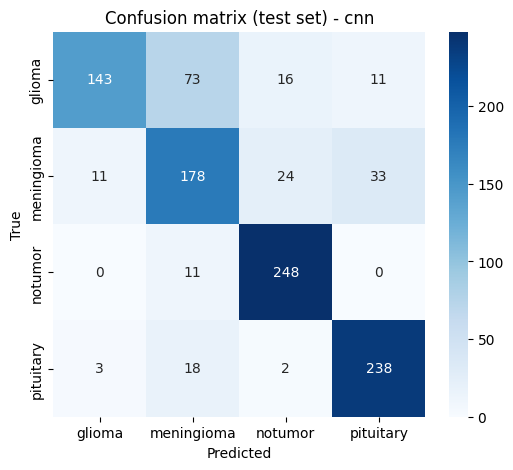

In [6]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title(f"Confusion matrix (test set) - {TAG}")
plt.savefig(f"../reports/confusion_matrix_{TAG}.png", dpi=150, bbox_inches="tight")
plt.show()

## Correct and incorrect predictions

Incorrect predictions are sorted from the most confident mistake down.

Correct: 807 | Incorrect: 202


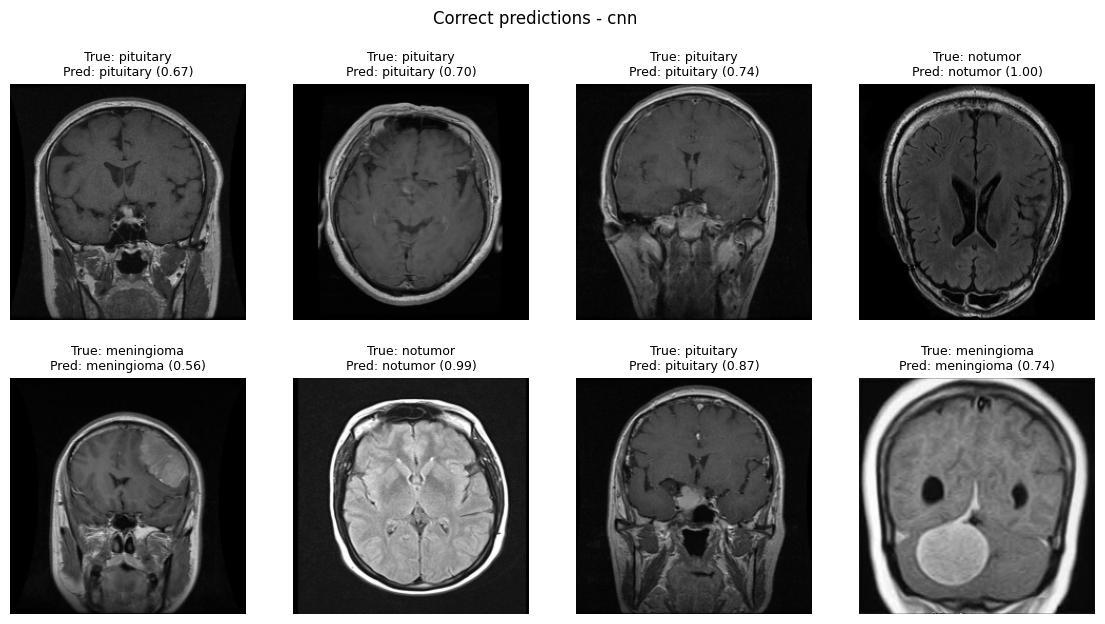

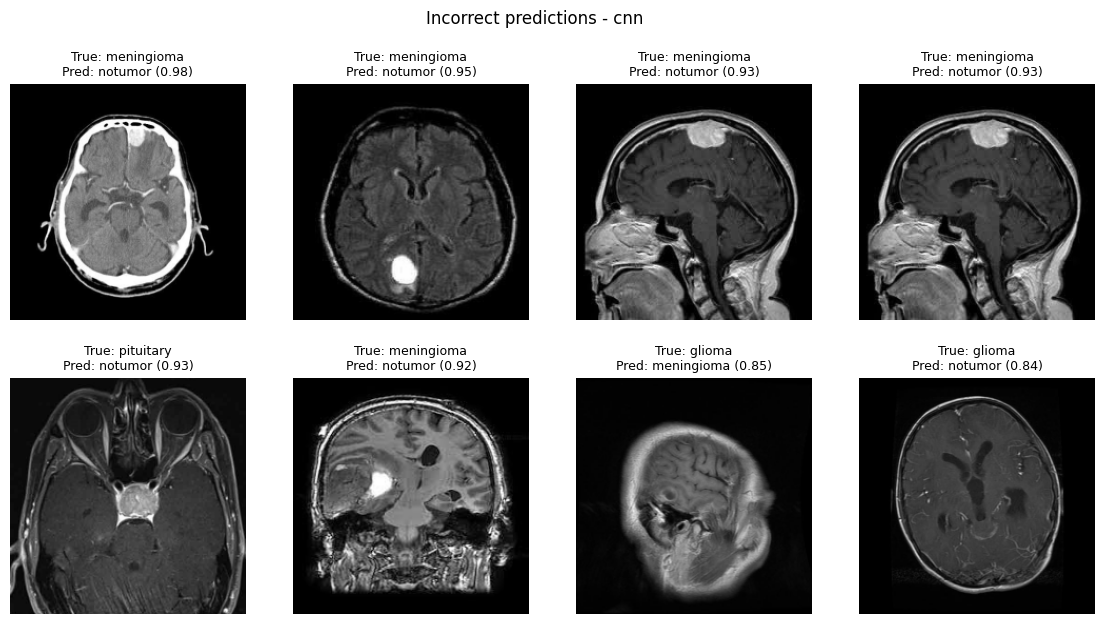

In [7]:
def show_examples(indices, title, filename):
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, i in zip(axes.ravel(), indices[:8]):
        ax.imshow(X_test[i])
        ax.set_title(
            f"True: {class_names[y_true[i]]}\nPred: {class_names[y_pred[i]]} ({probs[i].max():.2f})",
            fontsize=9,
        )
    fig.suptitle(title)
    plt.savefig(f"../reports/{filename}_{TAG}.png", dpi=150, bbox_inches="tight")
    plt.show()


correct = np.where(y_pred == y_true)[0]
wrong = np.where(y_pred != y_true)[0]
wrong = wrong[np.argsort(-probs[wrong].max(axis=1))]
print(f"Correct: {len(correct)} | Incorrect: {len(wrong)}")

show_examples(correct, f"Correct predictions - {TAG}", "correct_predictions")
show_examples(wrong, f"Incorrect predictions - {TAG}", "incorrect_predictions")

## Which classes get confused

In [8]:
pairs = {}
for true_idx, pred_idx in zip(y_true[wrong], y_pred[wrong]):
    key = f"{class_names[true_idx]} -> {class_names[pred_idx]}"
    pairs[key] = pairs.get(key, 0) + 1

for key, count in sorted(pairs.items(), key=lambda item: -item[1]):
    print(key, count)

glioma -> meningioma 73
meningioma -> pituitary 33
meningioma -> notumor 24
pituitary -> meningioma 18
glioma -> notumor 16
meningioma -> glioma 11
notumor -> meningioma 11
glioma -> pituitary 11
pituitary -> glioma 3
pituitary -> notumor 2


## Explainability with Grad-CAM (one test image per class)

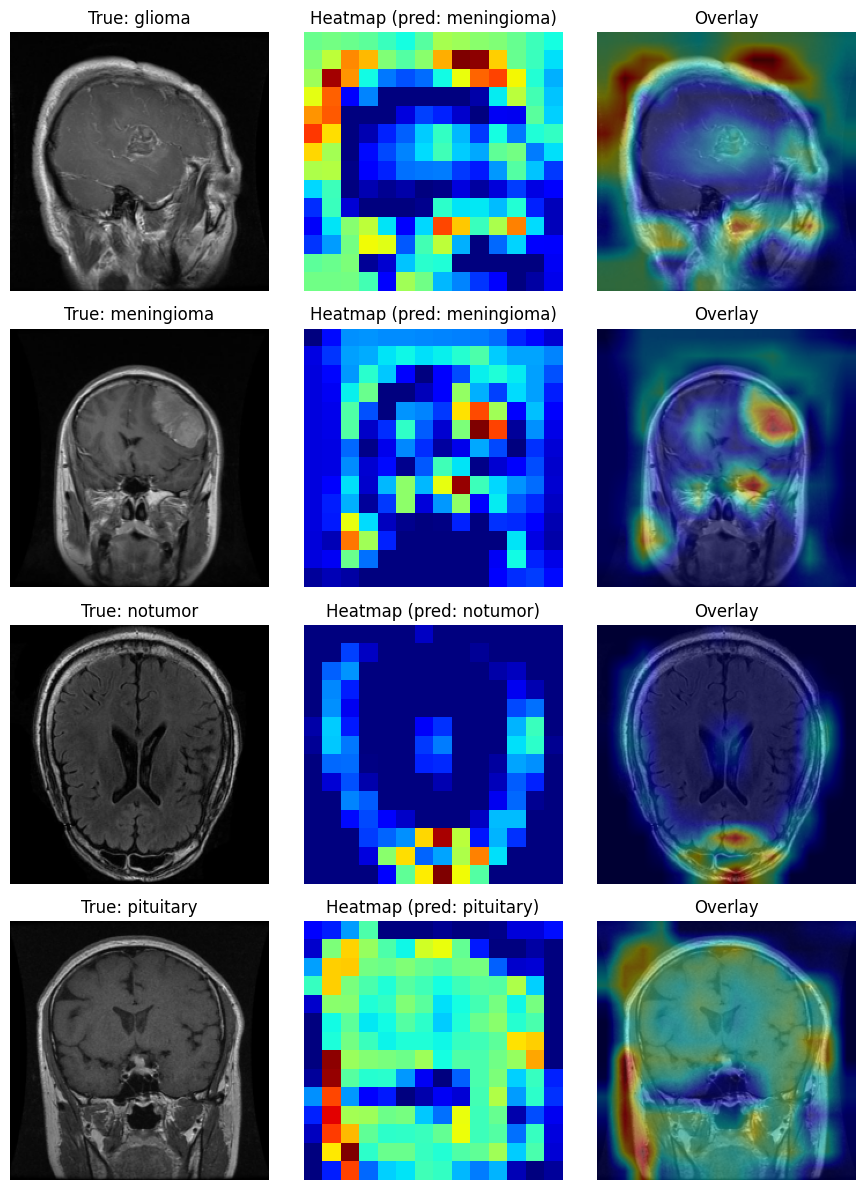

In [9]:
from neurovision.gradcam import make_gradcam_heatmap, overlay_heatmap

fig, axes = plt.subplots(len(CLASSES), 3, figsize=(9, 12))
for row, name in enumerate(class_names):
    idx = np.where(y_true == row)[0][0]
    img = X_test[idx]
    heatmap, pred_idx = make_gradcam_heatmap(model, img)
    axes[row, 0].imshow(img)
    axes[row, 0].set_title(f"True: {name}")
    axes[row, 1].imshow(heatmap, cmap="jet")
    axes[row, 1].set_title(f"Heatmap (pred: {class_names[pred_idx]})")
    axes[row, 2].imshow(overlay_heatmap(img, heatmap))
    axes[row, 2].set_title("Overlay")
    for ax in axes[row]:
        ax.axis("off")
plt.tight_layout()
plt.savefig(f"../reports/gradcam_{TAG}.png", dpi=150, bbox_inches="tight")
plt.show()

## predict_image: valid and invalid inputs

In [10]:
from neurovision.predict import predict_image

print(predict_image(p_test[0], model))

for bad_input in ["missing.jpg", "../README.md"]:
    try:
        predict_image(bad_input, model)
    except (FileNotFoundError, ValueError) as error:
        print(type(error).__name__, "->", error)

{'class': 'pituitary', 'confidence': 0.6662131547927856, 'probabilities': {'glioma': 0.007037907838821411, 'meningioma': 0.17284797132015228, 'notumor': 0.15390101075172424, 'pituitary': 0.6662131547927856}}
FileNotFoundError -> File not found: missing.jpg
ValueError -> Unsupported file type '.md'. Allowed: .bmp, .jpeg, .jpg, .png


## Save the metrics and log everything to MLflow

The metrics file feeds the Streamlit app (model comparison tab and automatic pixel-scale detection).

In [11]:
metrics = {
    "tag": TAG,
    "model_file": Path(MODEL_PATH).name,
    "test_accuracy": float(test_acc),
    "test_loss": float(test_loss),
    "macro_f1": float(report["macro avg"]["f1-score"]),
    "weighted_f1": float(report["weighted avg"]["f1-score"]),
    "n_test": int(len(X_test)),
    "input_size": [int(width), int(height)],
    "input_dtype": str(X_test.dtype),
    "input_min": float(X_test.min()),
    "input_max": float(X_test.max()),
    "per_class": {n: report[n] for n in class_names},
}
Path(f"../reports/metrics_{TAG}.json").write_text(json.dumps(metrics, indent=2))

files = [f"../reports/{name}_{TAG}.png" for name in
         ("confusion_matrix", "correct_predictions", "incorrect_predictions", "gradcam")]
files += [f"../reports/classification_report_{TAG}.txt", f"../reports/metrics_{TAG}.json"]
log_evaluation(TAG, MODEL_PATH, test_loss, test_acc, report, files=files)
mlflow.end_run()
print("Logged to MLflow and saved reports/metrics_%s.json" % TAG)

Logged to MLflow and saved reports/metrics_cnn.json


## Comparison of every model evaluated so far

In [12]:
import pandas as pd

rows = [json.loads(p.read_text()) for p in sorted(Path("../reports").glob("metrics_*.json"))]
pd.DataFrame(rows)[["tag", "model_file", "test_accuracy", "test_loss", "macro_f1", "weighted_f1", "n_test"]].round(4)

,tag,model_file,test_accuracy,test_loss,macro_f1,weighted_f1,n_test
0,cnn,best_model.keras,0.7998,0.5217,0.793,0.7959,1009
